# Autoresearch feature discovery

<a href="https://colab.research.google.com/github/sixhobbits/colab-demo/blob/main/cookbooks/autoresearch_feature_discovery/autoresearch_feature_discovery.ipynb" target="_blank"><img src="https://img.shields.io/badge/Open%20in%20Colab-F9AB00?style=for-the-badge&logo=googlecolab&logoColor=white" alt="Open in Colab" height="28"></a> <a href="https://github.com/sixhobbits/colab-demo/blob/main/cookbooks/autoresearch_feature_discovery/autoresearch_feature_discovery.ipynb" target="_blank"><img src="https://img.shields.io/badge/View%20on%20GitHub-24292F?style=for-the-badge&logo=github&logoColor=white" alt="View on GitHub" height="28"></a>

> **No API key needed.** The code downloads this cookbook's saved answers, so
> *Run all* replays every TypeSafe call from them. It needs no TypeSafe account
> and costs nothing. To call the API yourself, set `TYPESAFE_API_KEY` and
> `DOWNLOAD_CACHE = False`.

From [the docs page](https://console.typesafe.ai/docs/cookbooks/autoresearch_feature_discovery).

How polite will people find a message? In this cookbook we use 2,000 requests that
Wikipedia editors left on each other's talk pages, each rated for politeness by five
people.

As a control, we train a CatBoost regressor (gradient-boosted trees) on the raw text, using
its default text features, which represent each message by the words it contains. Its
error is only 11% lower than always predicting the mean rating, so which words a message
contains says little about how polite it reads.

In this cookbook an LLM, the proposer, writes questions about the messages. Jev answers
every question for every message, and CatBoost trains on the answers. CatBoost then reports
which questions it used and which messages it still gets wrong. The proposer reads that
report and suggests changes to the questions. A change stays only if it makes CatBoost's
predictions better, and each kept change is one step of the loop.

<img src="https://raw.githubusercontent.com/sixhobbits/colab-demo/main/cookbooks/autoresearch_feature_discovery/autoresearch_feature_discovery-diagram-f4a2836a49.png" alt="Diagram" width="1176">

The table scores each approach by RMSE: how far its predictions miss on the rating scale,
with big misses counting for more. Lower is better. Every number comes from 800 requests
the loop never saw.

| how the message becomes a rating | RMSE |
|---|---|
| predict the average rating of the training rows | 0.788 |
| the control: the same CatBoost, reading the raw text | 0.703 |
| ask Jev for the rating itself, with a line fitted to the training rows | 0.492 |
| 16 questions from the proposer's first call, no loop | 0.471 |
| **20 questions after five steps of the loop** | **0.456** |

The proposer's first call does most of the work. It was told nothing about politeness
research, and it wrote questions about thanks and praise, apologies and hedging (softened
wording), greetings, asking indirectly ("would you be willing to…"), and framing a request
as a shared "we" effort. A 2013 study of this corpus built a feature for each of those by
hand. Four more steps lowered the error by another 0.015, about 3%. One of them added a
question about "please" and similar courtesy words, another of the study's features, which
the first call had missed. The loop keeps a change only when it lowers the error on rows
the proposer never reads, so it turned down most of what the proposer suggested after
step 1 and ended with 20 questions.

By the end you have a loop you can run on your own labelled text, a curve of held-out error
per step, and a table of which questions the final model used most.

<Tip>
To take this notebook further or apply it to another problem, see
[Next steps](#next-steps).
</Tip>

In [ ]:
%pip install -q 'anthropic' 'openai' 'catboost' 'numpy' 'matplotlib' 'typesafe-sdk>=0.7.0' 'ipython' 'cooksafe>=0.3.0,<0.4.0'

In [ ]:
from __future__ import annotations

import json
import os
import random
import textwrap
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from time import perf_counter
from typing import NamedTuple

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from catboost import CatBoostRegressor
from cooksafe import JsonCache, make_playground_link
from IPython.display import Markdown, display
from typesafe_sdk import Noul, NoulCriteria, Score, TypeSafeClient

matplotlib.use("Agg")  # headless render

TYPESAFE_MODEL = "jev-1.14.0"  # the page's model; "jev-latest" runs the newest, live
FOLDS, REPEATS = 5, 3  # repeats steady the error at this sample size
CATBOOST = dict(
    iterations=400,
    depth=4,
    learning_rate=0.05,
    loss_function="RMSE",
    verbose=0,
    random_seed=0,
    thread_count=1,
    allow_writing_files=False,
)

client = TypeSafeClient(
    # keyless kernels replay the cache
    api_key=os.environ.get("TYPESAFE_API_KEY", "cache-only"),
    base_url=os.environ.get("TYPESAFE_ENDPOINT"),
    timeout=120.0,
)

EXAMPLES_URL = (
    "https://raw.githubusercontent.com/typesafe-ai/typesafe-public-examples/main/"
    "cookbooks/autoresearch_feature_discovery"
)


def download(name: str) -> Path:
    """Fetch one of this cookbook's files from typesafe-public-examples unless it is on disk."""
    path = Path(name)
    if not path.exists():
        urllib.request.urlretrieve(f"{EXAMPLES_URL}/{name}", path)
    return path


CACHE = Path("autoresearch_feature_discovery_cache.json")
# True fills CACHE with the published answers, so the run makes no requests. To run
# live, set it to False and delete CACHE; a CACHE already on disk is never overwritten.
DOWNLOAD_CACHE = True
if DOWNLOAD_CACHE:
    download(CACHE.name)
json_cache = JsonCache(CACHE)

# ----------------------------------------------------------------- the specification

INTENSITY_LEVELS = [
    "Not present in this message at all",
    "Barely present - a single small trace",
    "Present at a moderate level",
    "Present strongly - it marks the whole message",
    "Dominant - the message is defined by it",
]
PRESENCE_CRITERIA = NoulCriteria(
    true="The message shows this or clearly implies it",
    false="The message gives no indication of this",
)

# Asking for the rating outright: ten bands from hostile to gracious.
SCORE_LEVELS = [
    "Insults the reader or is openly hostile",
    "Curt and accusing, with no courtesy at all",
    "Blunt and demanding",
    "Abrupt, a bare question or order with no softening",
    "Neutral and businesslike",
    "Plain but carries a small courtesy",
    "Friendly, with some softening or thanks",
    "Warm and considerate of the reader",
    "Very courteous, thanking or apologising and asking gently",
    "Exceptionally gracious and deferential",
]

# Structured output requires every property in `required`, so unused fields come back empty.
PROPOSAL_SCHEMA = {
    "type": "object",
    "properties": {
        "actions": {
            "type": "array",
            "items": {
                "type": "object",
                "properties": {
                    "op": {"type": "string", "enum": ["add", "revise", "drop"]},
                    "target": {"type": "string"},
                    "name": {"type": "string"},
                    "kind": {"type": "string", "enum": ["intensity", "presence"]},
                    "question": {"type": "string"},
                },
                "required": ["op", "target", "name", "kind", "question"],
                "additionalProperties": False,
            },
        }
    },
    "required": ["actions"],
    "additionalProperties": False,
}

PROPOSALS = 18  # actions the proposer may return per call

# The one string that knows this is about politeness. Point it at your own label and text.
PROPOSER_TASK = f"""You are designing numeric features for a gradient-boosting model that
predicts how polite a request reads: the average of five people's ratings, normalised so that
0 is typical, negative is less polite and positive is more polite (most fall between -2 and 2).
Each message is a request one Wikipedia editor left on another editor's talk page. The model
sees nothing but the features you design.

Return up to {PROPOSALS} actions. Each action is one of:

- {{"op": "add", "target": "", "name": ..., "kind": ..., "question": ...}}
  A new feature.
- {{"op": "revise", "target": <name of an existing feature>, "name": ..., "kind": ...,
  "question": ...}}
  Replace that feature's question with better wording. Use this when a feature measures the
  right thing badly: too narrow, too vague, or worded so nearly every message answers the same.
- {{"op": "drop", "target": <name of an existing feature>, "name": "", "kind": "intensity",
  "question": ""}}
  Remove a feature that is not earning its place.

`kind` is "intensity" for something with a degree, or "presence" for a yes/no fact.
`question` is what gets asked about one message.

An "intensity" question is graded against this fixed five-level rubric, so word it so that the
levels make sense:
{chr(10).join(f"  {i}. {level}" for i, level in enumerate(INTENSITY_LEVELS))}

A "presence" question is answered as the probability that it is true of the message.

Good features can be judged from the message's own words, vary from message to message, and
carry information about politeness that the other features do not. Raters react to word choice,
how the writer frames the request, how they address the reader, and what they say about the
reader.

Write every question in your own words. Do not quote or closely paraphrase any one example
message in a question, not even as an "e.g.": describe the pattern it shows instead. Common words
and stock phrases that many messages use may still be named."""


class Split(NamedTuple):
    """The rows, their labels, and which rows each part of the loop may use."""

    messages: list[str]
    scores: np.ndarray
    dev: np.ndarray  # the rows the models train on
    read: np.ndarray  # dev rows the proposer may see
    check: np.ndarray  # dev rows that judge each change; the proposer never sees them
    test: np.ndarray  # held out, scored once at the end


# ----------------------------------------------------------------- the data

DATA = Path("wikipedia_politeness.json")
DATA_URL = (
    "https://raw.githubusercontent.com/typesafe-ai/typesafe-public-examples/main/"
    "cookbooks/autoresearch_feature_discovery/wikipedia_politeness.json"
)


@json_cache
def load_slice(n_dev: int, n_test: int, seed: int) -> dict:
    """Read the corpus and take a seeded sample of message + rating, one row per message."""
    if not DATA.exists():
        urllib.request.urlretrieve(DATA_URL, DATA)
    rows, seen = [], set()
    for row in json.loads(DATA.read_text(encoding="utf-8")):  # a few requests repeat verbatim
        if not row["text"] or row["text"] in seen:
            continue
        seen.add(row["text"])
        rows.append((row["text"], float(row["score"])))
    random.Random(seed).shuffle(rows)
    picked = rows[: n_dev + n_test]
    return {"messages": [r[0] for r in picked], "scores": [r[1] for r in picked]}


def example_rows(split: Split, out_of_fold: np.ndarray | None, n: int) -> list[int]:
    """Select the rows a proposal call reads, from the rows the proposer may see."""
    read = split.read
    if out_of_fold is None:
        ranked = read[np.argsort(split.scores[read], kind="stable")]
        return [int(ranked[round(q * (len(ranked) - 1))]) for q in np.linspace(0, 1, n)]
    error = np.abs(split.scores[read] - out_of_fold[read])
    order = np.argsort(-error, kind="stable")
    worst = [int(read[i]) for i in order[: n // 2]]
    best = [int(read[i]) for i in order[len(order) - (n - n // 2) :]]
    return worst + best


def example_block(
    rows: list[int],
    split: Split,
    out_of_fold: np.ndarray | None,
    previous: np.ndarray | None = None,
) -> str:
    """Format selected rows for the proposer."""
    if out_of_fold is None:
        head = "Example messages, with the rating each one was given:"
        body = [f"- rated {split.scores[r]:+.2f}: {split.messages[r]}" for r in rows]
        return head + "\n" + "\n".join(body)

    head = (
        "Dev messages, worst-predicted first. The first half is where your current questions "
        "miss by the most and the second half is where they are already right, so what "
        "separates the halves is what the questions have not captured."
    )
    if previous is not None:
        head += (
            " Each line also shows what the previous step predicted, so you can see which "
            "messages your last kept change moved."
        )
    body = []
    for r in rows:
        line = f"- rated {split.scores[r]:+.2f}, predicted {out_of_fold[r]:+.2f}"
        if previous is not None:
            line += f" (last step {previous[r]:+.2f})"
        body.append(f"{line}: {split.messages[r]}")
    return head + "\n" + "\n".join(body)


def load_split(n_dev: int, n_test: int, n_check: int, seed: int = 0) -> Split:
    # keyword, because the cache key is the function name plus how each argument was spelled
    data = load_slice(n_dev, n_test, seed=seed)
    return Split(
        messages=data["messages"],
        scores=np.array(data["scores"]),
        dev=np.arange(n_dev),
        read=np.arange(n_dev - n_check),
        check=np.arange(n_dev - n_check, n_dev),
        test=np.arange(n_dev, n_dev + n_test),
    )


# ----------------------------------------------------------------- the proposer


def proposal_prompt(
    examples: str, feedback: str, accepted: list[dict], rejected: list[str]
) -> str:
    parts = [PROPOSER_TASK, "\n" + examples]
    if accepted:
        parts.append(
            "\nThe features you have now. `add` must not duplicate one of these; `revise` and "
            "`drop` refer to one by name:\n"
            + "\n".join(
                f"- {f['name']} ({f['kind']}): {f['question']}" for f in accepted
            )
        )
    if feedback:
        parts.append("\nHow the model did with those features:\n" + feedback)
    if rejected:
        parts.append(
            "\nChanges already tried and turned down, with the cross-validated RMSE before "
            f"and after. A change has to lower it by at least {MIN_GAIN}. Do not propose "
            "these again, or close variants of them:\n" + "\n".join(rejected)
        )
    return "\n".join(parts)


@json_cache
def propose(call: int, prompt: str, proposer: str) -> dict:
    """One proposal call. Every number in `prompt` is rounded so a replay hits the cache."""
    if proposer.startswith("claude"):
        import anthropic

        response = anthropic.Anthropic(
            api_key=os.environ.get("ANTHROPIC_API_KEY", "cache-only")
        ).messages.create(
            model=proposer,
            max_tokens=16000,
            output_config={
                "effort": "medium",
                "format": {"type": "json_schema", "schema": PROPOSAL_SCHEMA},
            },
            messages=[{"role": "user", "content": prompt}],
        )
        body = next(block.text for block in response.content if block.type == "text")
        usage = [response.usage.input_tokens or 0, response.usage.output_tokens or 0]
    else:
        from openai import OpenAI

        response = OpenAI(
            api_key=os.environ.get("OPENAI_API_KEY", "cache-only")
        ).chat.completions.create(
            model=proposer,
            reasoning_effort="high",
            max_completion_tokens=16000,
            response_format={"type": "json_object"},
            messages=[
                {
                    "role": "user",
                    "content": prompt
                    + "\n\nReply with JSON matching this schema:\n"
                    + json.dumps(PROPOSAL_SCHEMA),
                }
            ],
        )
        body = response.choices[0].message.content
        usage = [response.usage.prompt_tokens, response.usage.completion_tokens]
    return {"actions": json.loads(body)["actions"][:PROPOSALS], "usage": usage}


def slug(name: str, taken: set[str]) -> str:
    """Names become question ids and column labels, so keep them plain and unique."""
    base = (
        "".join(c if c.isalnum() else "_" for c in name.lower()).strip("_") or "feature"
    )
    candidate, n = base, 2
    while candidate in taken:
        candidate, n = f"{base}_{n}", n + 1
    return candidate


def to_candidates(actions: list[dict], accepted: list[dict], tag: str) -> tuple:
    """Split a proposal's actions into questions to answer and a list of names to drop."""
    live = {f["name"] for f in accepted}
    drops = [a["target"] for a in actions if a["op"] == "drop" and a["target"] in live]
    replacing = {
        a["target"] for a in actions if a["op"] == "revise" and a["target"] in live
    }
    # a revision may keep the name it replaces, since that feature is on its way out
    taken, candidates = live - replacing, []
    for action in actions:
        if action["op"] == "drop":
            continue
        if action["op"] == "revise" and action["target"] not in live:
            continue  # a revision of something that is not there
        name = slug(action["name"], taken)
        taken.add(name)
        candidates.append(
            {
                "id": f"{name}@{tag}",  # unique, so earlier tries keep their columns
                "name": name,
                "kind": action["kind"],
                "question": action["question"],
                "replaces": action["target"] if action["op"] == "revise" else "",
            }
        )
    return candidates, drops


# ----------------------------------------------------------------- the answers


def feature_questions(features: list[dict]) -> dict:
    questions = {}
    for feature in features:
        if feature["kind"] == "intensity":
            questions[feature["name"]] = Score(
                instructions=feature["question"], criteria=INTENSITY_LEVELS
            )
        else:
            questions[feature["name"]] = Noul(
                instructions=feature["question"], criteria=PRESENCE_CRITERIA
            )
    return questions


@json_cache
def answer(message: str, questions_json: str, model: str) -> dict:
    """One request per message, with every new question of the try. Keeps every probability."""
    questions = json.loads(questions_json)
    started = perf_counter()
    # the text goes under a named key that matches how the questions refer to it
    response = client.system_one(
        state={"message": message}, questions=questions, model=model
    )
    raw = {}
    for name, question in questions.items():
        got = response.answers[name]
        if question["type"] == "score":
            raw[name] = [
                got.probabilities.get(i, 0.0) for i in range(len(question["criteria"]))
            ]
        else:
            raw[name] = [got.noul]
    return {
        "raw": raw,
        "seconds": round(perf_counter() - started, 2),
        "input_tokens": response.usage.input_tokens or 0,
        "output_tokens": response.usage.output_tokens or 0,
    }


def featurize(messages: list[str], features: list[dict]) -> dict:
    """Answer one question set for many messages: one request each, four in flight."""
    questions = feature_questions(features)
    payload = json.dumps(
        {name: q.model_dump(mode="json", exclude_none=True) for name, q in questions.items()}
    )
    with ThreadPoolExecutor(max_workers=4) as pool:
        results = list(
            pool.map(lambda message: answer(message, payload, model=TYPESAFE_MODEL), messages)
        )
    return {
        f["name"]: np.array([r["raw"][f["name"]] for r in results], dtype=float)
        for f in features
    }


def encode(feature: dict, probabilities: np.ndarray, mode: str) -> list[tuple]:
    """Turn one question's probabilities into named columns."""
    name = feature["name"]
    if feature["kind"] == "presence":
        return [(name, probabilities[:, 0])]  # one number is all there is
    levels = np.arange(probabilities.shape[1])
    mean = probabilities @ levels
    if mode == "mean":
        return [(name, mean)]
    if mode == "mean_spread":
        variance = probabilities @ (levels**2) - mean**2
        return [(name, mean), (f"{name}_sd", np.sqrt(np.clip(variance, 0, None)))]
    return [(f"{name}_p{i}", probabilities[:, i]) for i in levels]


def design(features: list[dict], answers_for: dict, mode: str) -> tuple:
    """Stack every feature's columns into one matrix, plus a label per column."""
    columns, labels = [], []
    for feature in features:
        for label, column in encode(feature, answers_for[feature["id"]], mode):
            columns.append(column)
            labels.append(label)
    return np.column_stack(columns), labels


def plain(features: list[dict]) -> list[dict]:
    """What goes on the wire and into the cache key: no id, no bookkeeping."""
    return [
        {"name": f["name"], "kind": f["kind"], "question": f["question"]}
        for f in features
    ]


# ----------------------------------------------------------------- the fit


def rmse(y: np.ndarray, p: np.ndarray) -> float:
    return float(np.sqrt(np.mean((y - p) ** 2)))


def spearman(a: np.ndarray, b: np.ndarray) -> float:
    """Rank correlation: does the model order the messages the way the raters did?"""
    ranks = (
        np.argsort(np.argsort(a)).astype(float),
        np.argsort(np.argsort(b)).astype(float),
    )
    return float(np.corrcoef(*ranks)[0, 1])


def folds(y: np.ndarray, k: int, seed: int) -> list[np.ndarray]:
    """Label-stratified k-fold: sort by the label with a seeded tiebreak, then deal off the top."""
    rng = np.random.default_rng(seed)
    order = np.lexsort((rng.random(len(y)), y))
    return [np.sort(order[i::k]) for i in range(k)]


def cross_validate(
    X: np.ndarray, y: np.ndarray, scored: np.ndarray
) -> tuple[np.ndarray, float]:
    """Out-of-fold predictions for every row, and the error on the `scored` rows."""
    out_of_fold = np.zeros((REPEATS, len(y)))
    for repeat in range(REPEATS):
        for fold in folds(y, FOLDS, seed=repeat):
            train = np.setdiff1d(np.arange(len(y)), fold)
            model = CatBoostRegressor(**CATBOOST).fit(X[train], y[train])
            out_of_fold[repeat, fold] = model.predict(X[fold])
    scores = [rmse(y[scored], out_of_fold[repeat, scored]) for repeat in range(REPEATS)]
    return out_of_fold.mean(axis=0), float(np.mean(scores))


def importances(X: np.ndarray, y: np.ndarray) -> np.ndarray:
    return CatBoostRegressor(**CATBOOST).fit(X, y).get_feature_importance()


def paired_gain(y: np.ndarray, before: np.ndarray, after: np.ndarray) -> tuple:
    """Bootstrap the paired held-out RMSE change."""
    squared = ((y - before) ** 2, (y - after) ** 2)
    rng = np.random.default_rng(0)
    drawn = []
    for _ in range(2000):
        rows = rng.integers(0, len(y), len(y))
        drawn.append(
            np.sqrt(squared[1][rows].mean()) - np.sqrt(squared[0][rows].mean())
        )
    drawn = np.array(drawn)
    return (
        rmse(y, after) - rmse(y, before),
        float(np.percentile(drawn, 2.5)),
        float(np.percentile(drawn, 97.5)),
    )


def fit_predict(X: np.ndarray, split: Split) -> np.ndarray:
    model = CatBoostRegressor(**CATBOOST).fit(X[split.dev], split.scores[split.dev])
    return model.predict(X[split.test])


def fit_predict_text(split: Split) -> np.ndarray:
    """The reference arm: the same model, handed the message instead of the columns."""
    from catboost import Pool

    raw = np.array([[message] for message in split.messages], dtype=object)
    model = CatBoostRegressor(**CATBOOST).fit(
        Pool(raw[split.dev], split.scores[split.dev], text_features=[0])
    )
    return model.predict(Pool(raw[split.test], text_features=[0]))


def evaluate(
    features: list[dict], answers_for: dict, split: Split, mode: str
) -> tuple[np.ndarray, float]:
    """k-fold predictions for every dev row, and their error on the check rows."""
    X, _ = design(features, answers_for, mode)
    return cross_validate(X[split.dev], split.scores[split.dev], split.check)


def swap_in(accepted: list[dict], feature: dict) -> list[dict] | None:
    """The accepted set with `feature` in place of the one it revises, or None if it is gone."""
    at = next(
        (i for i, f in enumerate(accepted) if f["name"] == feature["replaces"]), None
    )
    if at is None:
        return None
    trial = list(accepted)
    trial[at] = {k: feature[k] for k in ("id", "name", "kind", "question")}
    return trial


def try_change(
    trial: list[dict],
    accepted: list[dict],
    cv: float,
    answers_for: dict,
    split: Split,
    mode: str,
    tolerance: float,
) -> tuple[list[dict], float, str, bool]:
    """Refit with the change and keep it only if check-row error improves. No API calls."""
    _, cv_trial = evaluate(trial, answers_for, split, mode)
    note = f"CV {cv:.3f} -> {cv_trial:.3f}"
    if cv_trial <= cv + tolerance:
        return trial, cv_trial, note, True
    return accepted, cv, note, False


def owner_of(label: str, features: list[dict]) -> dict:
    """Which feature a column label belongs to - encodings suffix the name."""
    exact = next((f for f in features if f["name"] == label), None)
    if exact:
        return exact
    return next(f for f in features if label.startswith(f["name"] + "_"))


def importance_per_feature(
    features: list[dict], labels: list[str], column_importances: np.ndarray
) -> dict:
    """Sum each question's CatBoost column importances.

    Intensity questions can produce multiple model columns. Combining their normalized
    importances gives one percentage share per question.
    """
    total = {f["name"]: 0.0 for f in features}
    for label, column_importance in zip(labels, column_importances):
        total[owner_of(label, features)["name"]] += float(column_importance)
    return total


def feedback_for(
    history: list[float],
    accepted: list[dict],
    answers_for: dict,
    split: Split,
    mode: str,
    out_of_fold: np.ndarray,
    previous: np.ndarray | None,
) -> str:
    """The scoreboard the next proposal call reads. The messages themselves arrive separately,
    through `example_block`. Numbers are rounded before they enter the prompt."""
    X, labels = design(accepted, answers_for, mode)
    dev, scores = split.dev, split.scores
    by_name = importance_per_feature(accepted, labels, importances(X[dev], scores[dev]))

    lines = ["Cross-validated RMSE so far, lower is better:"]
    lines += [f"  step {i + 1}: {v:.3f}" for i, v in enumerate(history)]
    if previous is not None:
        read = split.read
        now = np.abs(scores[read] - out_of_fold[read])
        before = np.abs(scores[read] - previous[read])
        better, worse = int((now < before - 0.1).sum()), int((now > before + 0.1).sum())
        lines.append(
            f"\nAgainst the previous step, {better} of {len(read)} dev messages are now "
            f"predicted better by more than 0.1 and {worse} are predicted worse."
        )
    lines.append(
        "\nYour features, with importance as a percentage of the total and the spread of the "
        "column across the dev rows. Low importance or low spread means the question is not "
        "doing much; revise or drop it."
    )
    for feature in sorted(accepted, key=lambda f: -by_name.get(f["name"], 0.0)):
        column = encode(feature, answers_for[feature["id"]], mode)[0][1]
        lines.append(
            f"  {feature['name']} ({feature['kind']}): "
            f"{by_name.get(feature['name'], 0.0):.1f}% importance, "
            f"spread {column[dev].std():.2f}"
        )
    return "\n".join(lines)


# ----------------------------------------------------------------- the loop itself


class Discovery(NamedTuple):
    """Artifacts returned by the discovery loop."""

    accepted: list[dict]  # the question set it ended with
    answers_for: dict  # feature id -> (rows x levels) probabilities
    snapshots: list[list[dict]]  # the set as it stood at the end of each step
    history: list[float]  # check-row error after each step
    journal: list[tuple]  # every change tried, and what became of it
    stop: list[str]  # why the loop ended


def describe(what: str, feature: dict | None, name: str) -> str:
    """One line for the proposer's list of changes the check turned down."""
    if feature is None:
        return f"drop {name}"
    if feature["replaces"]:
        return f"revise {feature['replaces']} to ({feature['kind']}): {feature['question']}"
    return f"add {feature['name']} ({feature['kind']}): {feature['question']}"


def try_changes(
    step: int,
    attempt: int,
    actions: list[dict],
    run: Discovery,
    rejected: list[str],
    split: Split,
    mode: str,
    min_spread: float,
    min_gain: float,
) -> int:
    """Answer one proposal's new questions, test each change, and return how many stayed."""
    accepted, answers_for, journal = run.accepted, run.answers_for, run.journal
    keep, drops = to_candidates(actions, accepted, f"{step}.{attempt}")
    if keep:  # one request per row, carrying every new question of this try
        answers = featurize(split.messages, plain(keep))
        for feature in keep:
            answers_for[feature["id"]] = answers[feature["name"]]

    def log(what: str, feature: dict | None, name: str, note: str, took: bool) -> int:
        journal.append((step, attempt, what, name, note))
        if not took:
            rejected.append(f"- {describe(what, feature, name)} ({note})")
        return int(took)

    # step 1's questions are the starting set; after that, every change has to earn its
    # place by lowering check-row error by at least min_gain
    cv = evaluate(accepted, answers_for, split, mode)[1] if accepted else None
    gain_args = (answers_for, split, mode, -min_gain)
    kept = 0

    for feature in [f for f in keep if not f["replaces"]]:  # every add is tried
        column = encode(feature, answers_for[feature["id"]], mode)[0][1]
        if float(column[split.dev].std()) < min_spread:
            kept += log("flat", feature, feature["name"], "answers barely vary", False)
            continue
        added = {k: feature[k] for k in ("id", "name", "kind", "question")}
        if cv is None:  # step 1: nothing to compare against yet
            accepted.append(added)
            kept += log("add", feature, feature["name"], "", True)
            continue
        accepted[:], cv, note, took = try_change(accepted + [added], accepted, cv, *gain_args)
        kept += log("add" if took else "skip", feature, feature["name"], note, took)
    if cv is None and accepted:  # step 1 just built the starting set
        _, cv = evaluate(accepted, answers_for, split, mode)

    for feature in [f for f in keep if f["replaces"]]:  # every revision is tried
        trial = swap_in(accepted, feature)
        if trial is None:  # it revises something an earlier step already dropped
            continue
        accepted[:], cv, note, took = try_change(trial, accepted, cv, *gain_args)
        if feature["replaces"] != feature["name"]:
            note = f"was {feature['replaces']}, {note}"
        kept += log("revise" if took else "reject", feature, feature["name"], note, took)

    for name in drops:  # and every drop
        trial = [f for f in accepted if f["name"] != name]
        if not trial:
            continue
        accepted[:], cv, note, took = try_change(trial, accepted, cv, *gain_args)
        kept += log("drop" if took else "keep", None, name, note, took)

    report(step, attempt, journal, accepted, cv, kept)
    return kept


def run_loop(
    split: Split,
    max_steps: int,
    tries: int,
    max_proposals: int,
    examples: int,
    mode: str,
    min_spread: float,
    min_gain: float,
) -> Discovery:
    """Propose, answer and test until a change stays; that is one step. Repeat."""
    run = Discovery([], {}, [], [], [], [])
    shown = example_rows(split, None, examples)  # step 1 has nothing predicted yet
    out_of_fold = previous = None
    feedback, rejected, calls = "", [], 0

    for step in range(1, max_steps + 1):
        for attempt in range(1, tries + 1):
            if calls == max_proposals:
                run.stop.append(f"stopped at the cap of {max_proposals} proposal calls")
                return run
            calls += 1
            block = example_block(shown, split, out_of_fold, previous)
            prompt = proposal_prompt(block, feedback, run.accepted, rejected)
            actions = propose(calls, prompt, proposer=PROPOSER)["actions"]
            args = (run, rejected, split, mode, min_spread, min_gain)
            if try_changes(step, attempt, actions, *args):
                break
        else:  # every try of this step was turned down
            run.stop.append(f"stopped: step {step} kept nothing in {tries} tries")
            return run

        previous, (out_of_fold, cv) = (
            out_of_fold,
            evaluate(run.accepted, run.answers_for, split, mode),
        )
        run.history.append(cv)
        run.snapshots.append(list(run.accepted))
        feedback = feedback_for(
            run.history, run.accepted, run.answers_for, split, mode, out_of_fold, previous
        )
        # the next step reads the rows these questions get most wrong, and as many they get right
        shown = example_rows(split, out_of_fold, examples)

    run.stop.append(f"stopped at the cap of {max_steps} steps")
    return run


def report(
    step: int,
    attempt: int,
    journal: list[tuple],
    accepted: list[dict],
    cv: float,
    kept: int,
) -> None:
    """One block per try: what it proposed, then every change with its check-row error."""
    this_try = [j[2:] for j in journal if j[:2] == (step, attempt)]
    print(f"step {step}, try {attempt}:" if step > 1 else "step 1:")
    added = [name for what, name, note in this_try if what == "add" and not note]
    if added:
        print(
            textwrap.fill(
                ", ".join(added),
                88,
                initial_indent="  added  ",
                subsequent_indent=" " * 9,
            )
        )
    numbered = [(what, name, note) for what, name, note in this_try if note]
    width = max((len(name) for _, name, _ in numbered), default=0) + 2
    for what, name, note in numbered:  # everything carrying a number of its own
        print(f"  {what:<7}{name:<{width}}{note}")
    if kept:
        print(f"  -> {len(accepted)} features, check-row RMSE {cv:.3f}\n")
    else:
        print("  -> nothing kept\n")


# ----------------------------------------------------------------- asking for the score


POLITENESS = Score(
    instructions="How polite is this message toward the editor it is addressed to?",
    criteria=SCORE_LEVELS,
)


@json_cache
def ask_score(message: str, politeness: Score, model: str) -> dict:
    """One `Score` over ten politeness bands, read as its expected level, 0 to 9."""
    response = client.system_one(
        state={"message": message}, questions={"politeness": politeness}, model=model
    )
    got = response.answers["politeness"]
    return {
        "expected": sum(k * v for k, v in got.probabilities.items()),
        "picked": got.score,
        "input_tokens": response.usage.input_tokens or 0,
        "output_tokens": response.usage.output_tokens or 0,
    }


# ----------------------------------------------------------------- charts

CHART_PALETTES = {
    "light": {
        "surface": "#ffffff", "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781",
        "grid": "#e1e0d9", "axis": "#c3c2b7", "blue": "#2a78d6", "orange": "#eb6834",
    },
    "dark": {
        "surface": "#0d0a0f", "ink": "#fafafa", "ink2": "#d4d4d8", "muted": "#a1a1aa",
        "grid": "#2e2e33", "axis": "#52525b", "blue": "#5b9be8", "orange": "#f08050",
    },
}
_LIGHT = CHART_PALETTES["light"]  # the heatmap draws in the light palette only
SURFACE, INK, INK2, MUTED = _LIGHT["surface"], _LIGHT["ink"], _LIGHT["ink2"], _LIGHT["muted"]
GRID, AXIS, BLUE, ORANGE = _LIGHT["grid"], _LIGHT["axis"], _LIGHT["blue"], _LIGHT["orange"]


def style(ax, p: dict = _LIGHT) -> None:
    ax.set_facecolor(p["surface"])
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(p["axis"])
    ax.tick_params(colors=p["muted"], labelcolor=p["ink2"], labelsize=9)
    ax.set_axisbelow(True)


def polarity(feature: dict, answers_for: dict, split: Split) -> float:
    """Rank correlation between a question's answer and the rating, on the dev rows.

    Positive means a higher answer goes with a more polite message, negative the opposite. It is
    what orders the rows of the feature map, so the map reads as a gradient that flips.
    """
    column = encode(feature, answers_for[feature["id"]], "mean")[0][1]
    return spearman(column[split.dev], split.scores[split.dev])


def messages_heatmap(
    plt,
    questions: list[dict],
    answers_for: dict,
    split: Split,
    rows: tuple,
):
    """Compare held-out messages across the discovered questions, best-signal first.

    Rows arrive sorted from the questions that rise with the rating to the ones that fall with
    it, so a row above the divider shades left to right and a row below it shades right to
    left.
    """

    def value_of(feature: dict, row: int) -> float:
        return float(encode(feature, answers_for[feature["id"]], "mean")[0][1][row])

    signs = [polarity(question, answers_for, split) for question in questions]
    flip = next((i for i, s in enumerate(signs) if s < 0), len(questions))

    raw = np.array(
        [[value_of(question, row) for row in rows] for question in questions]
    )
    normalized = np.array(
        [
            values / (4 if question["kind"] == "intensity" else 1)
            for question, values in zip(questions, raw)
        ]
    )
    cmap = matplotlib.colors.LinearSegmentedColormap.from_list(
        "typesafe_heat", [SURFACE, "#f7c7ad", ORANGE]
    )
    height = 1.8 + 0.58 * len(questions)
    fig, ax = plt.subplots(figsize=(9.5, height), facecolor=SURFACE)
    image = ax.imshow(normalized, aspect="auto", cmap=cmap, vmin=0, vmax=1)
    row_labels = []
    for question, sign in zip(questions, signs):
        kind = "score" if question["kind"] == "intensity" else "noul"
        prefix = f"{sign:+.2f} ({kind}) "
        lines = textwrap.wrap(
            " ".join(question["question"].split()),
            width=52,
            max_lines=2,
            placeholder="...",
            break_long_words=False,
            break_on_hyphens=False,
        )
        row_labels.append(prefix + (f"\n{' ' * len(prefix)}").join(lines))
    column_labels = [
        f"#{i}\nrated {split.scores[row]:+.2f}\n{' '.join(split.messages[row].split())[:15]}..."
        for i, row in enumerate(rows, 1)
    ]
    ax.set_yticks(np.arange(len(questions)), row_labels)
    ax.set_xticks(np.arange(len(rows)), column_labels)
    ax.tick_params(
        axis="x", top=True, labeltop=True, bottom=False, labelbottom=False, pad=8
    )
    ax.tick_params(axis="y", labelsize=8.5)
    for side in ax.spines.values():
        side.set_visible(False)
    ax.set_xticks(np.arange(-0.5, len(rows), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(questions), 1), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.tick_params(which="minor", bottom=False, left=False)
    for i, question in enumerate(questions):
        for j, value in enumerate(raw[i]):
            label = (
                f"{value:.1f}" if question["kind"] == "intensity" else f"{value:.2f}"
            )
            color = SURFACE if normalized[i, j] > 0.58 else INK2
            ax.text(j, i, label, ha="center", va="center", color=color, fontsize=8)
    # the line where the questions stop rising with the score and start falling with it
    if 0 < flip < len(questions):
        ax.axhline(flip - 0.5, color=INK, linewidth=1.2)
        ax.annotate(
            "below this line, a higher answer means a less polite message",
            (len(rows) - 0.5, flip - 0.5),
            xytext=(-4, -3),
            textcoords="offset points",
            va="top",
            ha="right",
            color=INK2,
            fontsize=8.5,
            bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5),
        )
    colorbar = fig.colorbar(image, ax=ax, fraction=0.025, pad=0.025)
    colorbar.set_ticks([0, 0.5, 1])
    colorbar.set_label("normalized answer", color=INK2, fontsize=8.5)
    colorbar.ax.tick_params(labelsize=8, colors=INK2)
    # title and subtitle placed in inches from the top, so they hold at any number of rows
    fig.suptitle(
        "Every question, on five held-out messages from least to most polite",
        x=0.01,
        y=1 - 0.05 / height,
        ha="left",
        color=INK,
        fontsize=11,
    )
    fig.text(
        0.01,
        1 - 0.32 / height,
        "sorted by how the answer moves with the rating, so each row above the line shades "
        "left to right and each row below it shades the other way",
        color=MUTED,
        fontsize=9,
    )
    fig.text(
        0.01,
        0.005,
        "Row labels lead with the rank correlation between that question's answer and the "
        "rating. Cell text is each question's native scale: score 0-4, noul 0-1.",
        color=MUTED,
        fontsize=8.5,
    )
    return fig


def steps_chart(
    plt,
    curve: list[tuple],
    history: list[float],
    n_test: int,
    gain: tuple,
    p: dict = _LIGHT,
):
    """Check-row error and held-out error per step. The trend is the point, not the gap."""
    steps = list(range(1, len(curve) + 1))
    values = [v for _, v in curve]

    fig, ax = plt.subplots(figsize=(7, 3.9), facecolor=p["surface"])
    style(ax, p)
    ax.grid(axis="y", color=p["grid"], linewidth=0.8)
    # shade the gap between what the loop optimises and what it buys
    ax.fill_between(steps, history, values, color=p["grid"], alpha=0.75, linewidth=0)
    ax.plot(
        steps,
        history,
        marker="o",
        color=p["blue"],
        linewidth=2,
        linestyle="--",
        label="check rows - what the loop optimises",
    )
    ax.plot(
        steps,
        values,
        marker="o",
        color=p["orange"],
        linewidth=2,
        label="held out - what that actually buys",
    )
    # label each point on the outside of the pair, so neither line crowds its own numbers
    for x, dev_value, test_value in zip(steps, history, values):
        for value, other in ((dev_value, test_value), (test_value, dev_value)):
            ax.annotate(
                f"{value:.3f}",
                (x, value),
                textcoords="offset points",
                xytext=(0, 8 if value >= other else -16),
                ha="center",
                color=p["ink2"],
                fontsize=8.5,
            )
    ax.set_xticks(
        steps, [f"step {x}\n{n} features" for x, (n, _) in zip(steps, curve)]
    )
    ax.set_ylabel("RMSE (lower is better)", color=p["ink2"], fontsize=9)
    # tight around the two lines: the whole finding lives in a narrow band
    low, high = min(values + history), max(values + history)
    pad = max(high - low, 0.005)
    ax.set_ylim(low - 0.6 * pad, high + 0.3 * pad)
    difference, low_ci, high_ci = gain
    ax.set_title(
        f"{len(steps)} steps of the loop, scored on {n_test} held-out messages",
        loc="left",
        color=p["ink"],
        fontsize=11,
        pad=20,
    )
    # the number the chart is really about: is the held-out move bigger than the noise?
    ax.text(
        0,
        1.015,
        f"step 1 to step {len(steps)}, held out: {difference:+.3f} RMSE, "
        f"95% CI [{low_ci:+.3f}, {high_ci:+.3f}]",
        transform=ax.transAxes,
        color=p["muted"],
        fontsize=9,
    )
    ax.legend(frameon=False, labelcolor=p["ink2"], fontsize=9, loc="lower left")
    return fig

## Setup

Requires Python 3.10 or later. Choose a package manager to install the dependencies:

<Tabs sync={false}>
  <Tab title="pip">
    Create a virtual environment and add the dependencies:

    ```bash wrap
    python3 -m venv .venv
    .venv/bin/pip install anthropic openai catboost numpy matplotlib ipython 'cooksafe>=0.3.0,<0.4.0'
    ```
  </Tab>
  <Tab title="uv">
    Initialize a project and add the dependencies:

    ```bash wrap
    uv init --bare
    uv add anthropic openai catboost numpy matplotlib ipython 'cooksafe>=0.3.0,<0.4.0'
    ```
  </Tab>
</Tabs>

Set `TYPESAFE_API_KEY` and `ANTHROPIC_API_KEY`. The code downloads the published answers
into `autoresearch_feature_discovery_cache.json`, so the run makes no requests; to run
live, set `DOWNLOAD_CACHE = False` and delete that file. The `propose()` function also has
a branch for `gpt-5.6-luna`. It needs `OPENAI_API_KEY`, and this run did not use it.

The numbers below came from `jev-1.14.0` and `claude-sonnet-5` on 2026-11-05.

The first code cell holds the whole implementation: the API calls, the code that turns
answers into columns, the metrics and the chart styling. It is there so this file runs on
its own, and the docs site shows it folded. Skip it on a first read; the recipe starts in
the next cell.

In [ ]:
N_DEV, N_TEST = 1200, 800  # the loop reads dev labels only; test is scored once
N_CHECK = 400  # dev rows that judge each change; the proposer never sees them
MAX_STEPS = 5  # step 1 is the first proposal; each later step ends when a change stays
TRIES = 3  # a step that keeps nothing in this many tries ends the loop
MAX_PROPOSALS = 12  # proposal calls in all; each try asks Jev about all 2,000 rows
PROPOSER = "claude-sonnet-5"  # or "gpt-5.6-luna"
EXAMPLES = 60  # messages the proposer reads per try, half of them its worst misses
MIN_SPREAD = 0.05  # a column this flat cannot separate anything, so it is not kept
MIN_GAIN = 0.003  # after step 1, a change stays only if check-row error falls this much
ENCODING = "mean_spread"  # a score answer becomes two columns: its mean and spread

split = load_split(N_DEV, N_TEST, N_CHECK, seed=0)
MESSAGES, SCORES, DEV, TEST = split.messages, split.scores, split.dev, split.test

print(
    f"{len(DEV)} dev rows, {len(TEST)} held out; ratings run "
    f"{SCORES.min():+.2f} to {SCORES.max():+.2f}, mean {SCORES.mean():+.2f}, sd {SCORES.std():.2f}"
)
for row in (int(np.argmin(SCORES[DEV])), int(np.argmax(SCORES[DEV]))):
    print(f"\nrated {SCORES[row]:+.2f}:\n{MESSAGES[row]}")

1200 dev rows, 800 held out; ratings run -2.78 to +2.35, mean -0.01, sd 0.76

rated -2.62:
Don't add any more trash to the article. Got it?

rated +2.24:
Although I have yet to understand what some of your maps mean, they are superb! Have you ever considered professional cartography?


## Load the rated requests

Each row is a request from the Wikipedia half of the Stanford Politeness Corpus. Five
annotators rated each one, and the label is the average of their normalised ratings: 0 is a
typical request, below 0 is blunter, above 0 is more courteous. The two requests printed
above are the least and most polite among the dev rows, the rows the loop learns from.

The requests are short, from one sentence to a few, and the raters judged each message as a
whole. The same word can push either way: "thanks" makes a sincere request read as more
polite and a sarcastic one read as less polite. The five raters also disagree with each
other, so no model can get the error to zero.

The `load_slice` function takes a random sample of 2,000 of the corpus's 4,338 distinct
requests, with a fixed seed so every run gets the same sample. The code splits them three
ways:

- **800 read rows.** The proposer reads its example messages from these, 60 per try.
- **400 check rows.** The proposer never sees these. A change stays only if it lowers the
  error here. A question written to fix messages the proposer has read would score well on
  those same messages, so they can't be the judge.
- **800 held-out rows.** Nothing in the loop touches these. They are scored once, at the
  end, and every number in the table at the top comes from them.

The read and check rows together are the 1,200 dev rows, and CatBoost trains on all of
them.

## Turn each answer into columns

Each proposed question is one of two kinds, and the kind decides how its answer becomes
columns of numbers for CatBoost.

- **`intensity`** becomes a `Score`, for anything that comes in degrees. Its five levels
  are printed below. The first column is the average level, weighted by Jev's probability
  for each level, so a message that sits between "moderate" and "strongly" comes out
  between the two. The second column is how widely that probability is spread around the
  average.
- **`presence`** becomes a `Noul`, for a yes/no fact like whether the writer says thanks.
  Its one column is that probability.

Each request sends the text to Jev as `{"message": text}`, because the questions refer to
it as "the message".

In [ ]:
print("every intensity question is graded on these five levels:\n")
for i, level in enumerate(INTENSITY_LEVELS):
    print(f"  {i}. {level}")
print("\nevery presence question is judged true or false against these:\n")
print(f"  true:  {PRESENCE_CRITERIA['true']}")
print(f"  false: {PRESENCE_CRITERIA['false']}")
print("\nthe brief the proposer works from:\n")
print("\n".join(PROPOSER_TASK.splitlines()[:6]) + "\n  ...")

every intensity question is graded on these five levels:

  0. Not present in this message at all
  1. Barely present - a single small trace
  2. Present at a moderate level
  3. Present strongly - it marks the whole message
  4. Dominant - the message is defined by it

every presence question is judged true or false against these:

  true:  The message shows this or clearly implies it
  false: The message gives no indication of this

the brief the proposer works from:

You are designing numeric features for a gradient-boosting model that
predicts how polite a request reads: the average of five people's ratings, normalised so that
0 is typical, negative is less polite and positive is more polite (most fall between -2 and 2).
Each message is a request one Wikipedia editor left on another editor's talk page. The model
sees nothing but the features you design.

  ...


## Run the loop

```
step 1: questions <- LLM(brief, 60 read rows across the rating range)
        answers[q] <- Jev(message, questions) for every row
repeat for each later step, up to MAX_STEPS:
    repeat up to TRIES times:
        messages <- the 30 worst-predicted read rows + the 30 best,
                    each with its rating, this prediction and the last step's
        actions  <- LLM(brief, questions, messages, importance and error so far,
                        every change already turned down)
        answers[q] <- Jev(message, this try's new questions) for every row
        for each add, revision or drop: refit; keep it if check-row error falls by MIN_GAIN
        if anything was kept: the step is done
    if no try kept anything: stop
    out_of_fold <- k-fold CatBoost on the columns   # picks the next step's messages
```

No proposed question is screened out before Jev answers it. Jev answers all of a try's
new questions about a message in one request, so an extra question costs no extra request.
A question that applies to one row in ten can look useless in the 60 messages the proposer
reads and still turn out to be the most useful column in the set.

The k-fold step splits the dev rows into k parts and predicts each part with a CatBoost
model trained on the rest, so every dev row gets a prediction from a model that never saw
it. Those predictions do three jobs. Their error on the check rows judges every add,
revision and drop. Their misses on the read rows pick the messages the next step reads.
And they show the proposer how far its last kept change moved each message.

The brief, `PROPOSER_TASK`, is the instruction text the proposer gets every try. It ends
by telling the proposer not to quote any one example message in a question. Without that
line the proposer can copy phrases from the rows it was shown into its questions as
examples, and a question built around one row's wording looks tuned to that row.

The `run_loop` call below prints one block per try. Step 1's questions are the starting
set, so each goes straight in unless its column is flat, meaning almost the same value on
every dev row. After that, every change is tried first: refit with it, and keep it only if
check-row error falls by at least `MIN_GAIN`. Adds are checked too, because a narrow
question can add more noise to the model than it adds signal. A smaller gain is within the
noise of a score on 400 rows. A refit makes no API calls, so a rejected change costs
nothing extra. In the log, `skip` is an add that was turned down, `reject` a revision and
`keep` a drop.

A step ends as soon as one try keeps a change. A try that keeps nothing leaves the
question set and the predictions as they were, so the next try would see the same prompt
and propose much the same changes again. To stop that, every change the check turns down
goes into the next prompt with its check-row error before and after, and the proposer is
told not to suggest it again. If `TRIES` tries in a row keep nothing, the loop has run out
of ideas that help, and it stops. `MAX_STEPS` and `MAX_PROPOSALS` cap the run either way.

In [ ]:
run = run_loop(
    split, MAX_STEPS, TRIES, MAX_PROPOSALS, EXAMPLES, ENCODING, MIN_SPREAD, MIN_GAIN
)
print(run.stop[0])
accepted, answers_for = run.accepted, run.answers_for
snapshots, history = run.snapshots, run.history

step 1:
  added  rudeness_insult, hostile_accusation, gratitude_or_praise, softening_hedges,
         greeting_or_address, blunt_command, sarcasm_or_mockery, explanation_given,
         positive_framing_of_reader, curt_terseness, question_mark_politeness,
         exclamatory_emotion, personal_criticism_of_edit, collaborative_tone,
         doubt_questioning_competence, indirect_request
  -> 16 features, check-row RMSE 0.450

step 2, try 1:
  skip   rhetorical_challenge_question  CV 0.450 -> 0.447
  skip   genuine_information_seeking    CV 0.450 -> 0.456
  skip   third_party_complaint          CV 0.450 -> 0.451
  skip   self_deprecating_irony         CV 0.450 -> 0.451
  skip   nonstandard_or_foreign_text    CV 0.450 -> 0.453
  reject sarcasm_or_mockery             CV 0.450 -> 0.452
  reject doubt_questioning_competence   CV 0.450 -> 0.458
  reject curt_terseness                 CV 0.450 -> 0.449
  keep   explanation_given              CV 0.450 -> 0.456
  -> nothing kept

step 2, try 2:

## Point it at your own data

Inside the loop, the only string that mentions politeness is `PROPOSER_TASK`, and
`featurize()` takes any list of strings. Rewrite the brief for your own label and text.
Cached responses are looked up by prompt, so after an edit the next run calls the API
again for every try.

The request count grows with rows, not with questions: one request per row per try, so
100,000 rows is 100,000 requests a try, and `MAX_PROPOSALS` caps the number of tries. A
revision is a new question, so its answers are fetched for every row too. The code sends
four requests at a time. Eight at a time hit a rate limit on a shared key.

## Read what the questions measure

The chart below shows five held-out requests against the questions the final model uses
most: the top eight `Score` questions by importance, plus the three `Noul` questions the
loop kept. The requests are the least polite, the most polite, and three evenly spaced
between them.

Each row of the chart is a question, and each column is a request, least polite on the
left. The questions are sorted by which way their answer moves with the rating. Questions
whose answer rises with politeness sit above the divider, and questions whose answer falls
with it sit below. So reading left to right, the answers above the divider should climb
and the answers below it should fall.

the five held-out heatmap columns:

  1. rated -2.78: no, not funny, unless you are a mentally challenged person. Why don't you find a better hobby where 
  2. rated -0.50: On the third reading... Why not include an edit summary that tells me this? Why not revert my revert
  3. rated +0.02: Hey, when do we add games for the EHF Champion League and the Basketball EuroLeague into the portal?
  4. rated +0.56: I was trying to create a subpage. Could you please make it a subpage for me?
  5. rated +2.35: I'm an admin, I'd be happy to do it. You want me to do it now?


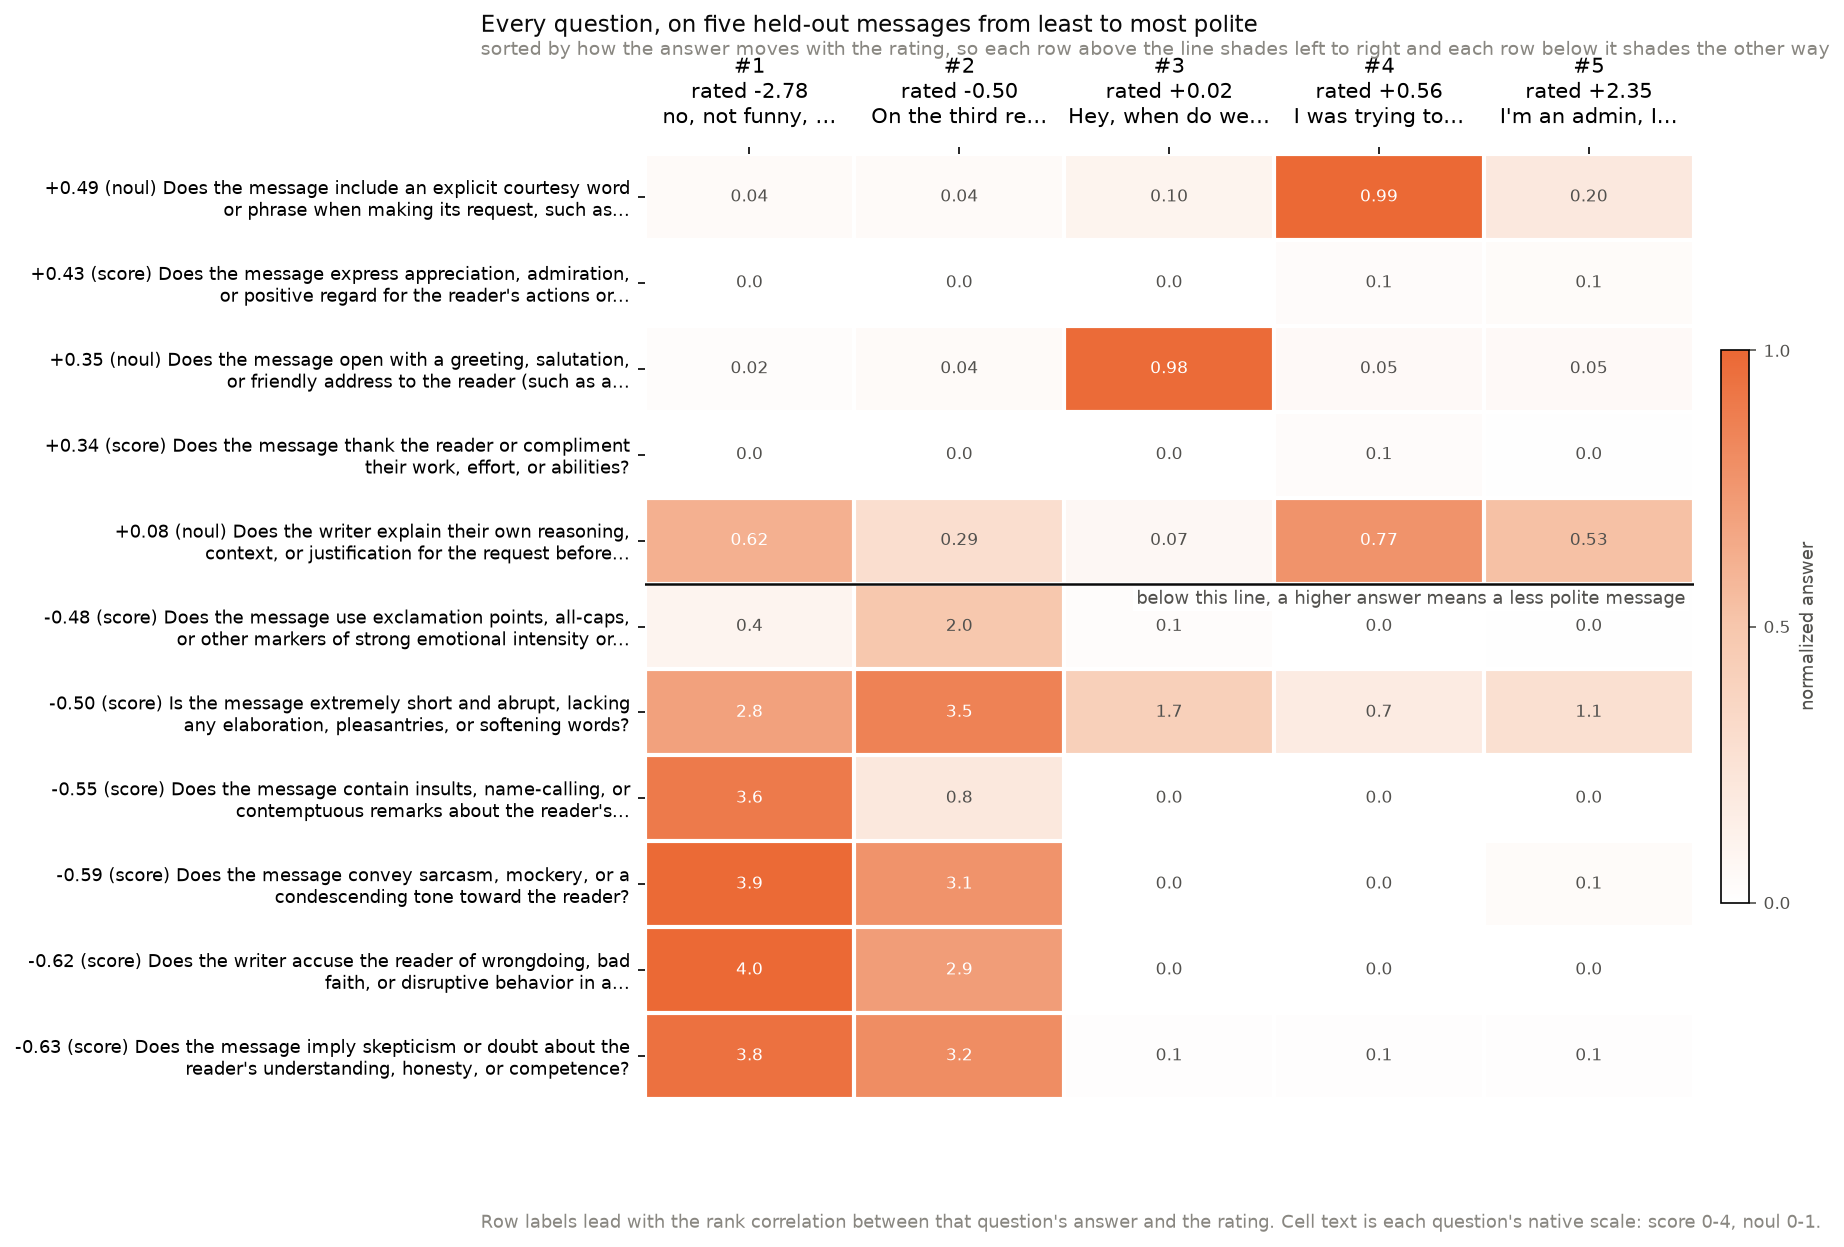

In [ ]:
X, labels = design(accepted, answers_for, ENCODING)
column_importances = importances(X[DEV], SCORES[DEV])
# an encoding gives a feature more than one column, so add a feature's columns back up
feature_importances = importance_per_feature(accepted, labels, column_importances)
ranked = sorted(accepted, key=lambda f: -feature_importances[f["name"]])
score_questions = [f for f in ranked if f["kind"] == "intensity"][:8]
noul_questions = [f for f in ranked if f["kind"] == "presence"][:7]
# ordered by which way the answer moves with the rating, so the map flips halfway down
heatmap_questions = sorted(
    score_questions + noul_questions,
    key=lambda f: -polarity(f, answers_for, split),
)
ordered_test = TEST[np.argsort(SCORES[TEST], kind="stable")]
positions = np.linspace(0, len(ordered_test) - 1, 5).round().astype(int)
heatmap_rows = tuple(ordered_test[positions])

print("the five held-out heatmap columns:\n")
for i, row in enumerate(heatmap_rows, 1):
    excerpt = " ".join(MESSAGES[row].split())
    print(f"  {i}. rated {SCORES[row]:+.2f}: {excerpt[:100]}")

fig = messages_heatmap(plt, heatmap_questions, answers_for, split, heatmap_rows)
display(fig)
plt.close(fig)

The two least polite requests score high on the accusation, doubt, sarcasm and insult rows
below the divider, and #2 is also the curtest. Request #3 opens with "Hey" and lights up
the greeting row, and #4, "Could you please make it a subpage for me?", is the one with a
courtesy word. Request #5, the most polite, is an admin offering to do the job. It scores
low on every row above the divider except the one about explaining a request. What makes
it polite is the offer itself. The offer-of-help question that step 2 added ranks too low
to make this chart, and it gives #5 a 3.9 out of 4.

## Score every approach on the held-out rows

The cell below computes the table from the top of the page. All five approaches are
scored once on the same 800 held-out rows, and the first three use none of the loop's
questions. The first predicts the mean dev rating for every row and reads nothing from the
message. The second is the control: the same CatBoost, reading the raw text with its
default text features. The third asks Jev for the rating directly.

That third approach is one `Score` question per row over ten bands, from "insults the
reader or is openly hostile" up to "exceptionally gracious and deferential". Its answer is
a level from 0 to 9, and nothing in the question says where those levels fall on this
corpus's rating scale. So the code fits a straight line from level to rating on the dev
rows. The line's two numbers, slope and intercept, are the only thing this approach learns
from the ratings.

In the printed table, `vs mean` is each approach's RMSE divided by the RMSE of predicting
the mean. The `spearman` column is rank correlation: 1.0 would mean the held-out requests
come out in exactly the raters' order. The control is CatBoost's default text handling,
not a tuned text model. All of this is one dataset and one run of the loop.

In [ ]:
predicted = fit_predict(X, split)
text_predicted = fit_predict_text(split)

# ask Jev for the rating itself, one request per row
with ThreadPoolExecutor(max_workers=4) as pool:
    direct = list(
        pool.map(lambda message: ask_score(message, POLITENESS, model=TYPESAFE_MODEL), MESSAGES)
    )
asked = np.array([d["expected"] for d in direct])
# two numbers, both from the dev labels: where the levels sit on the rating scale
slope, intercept = np.polyfit(asked[DEV], SCORES[DEV], 1)

# what one proposal call gets you, before any feedback: the set step 1 ended with
first_step, _ = design(snapshots[0], answers_for, ENCODING)

mean_error = rmse(SCORES[TEST], np.full(len(TEST), SCORES[DEV].mean()))
print(f"{'arm':<48}{'RMSE':>7}{'vs mean':>9}{'spearman':>10}")
for label, p in (
    ("predict the mean of the dev rows", np.full(len(TEST), SCORES[DEV].mean())),
    ("the control: same CatBoost, raw text", text_predicted),
    ("ask for the rating itself, line fitted on dev", slope * asked[TEST] + intercept),
    (
        f"{len(snapshots[0])} questions from step 1, no loop",
        fit_predict(first_step, split),
    ),
    (f"{len(accepted)} questions after {len(snapshots)} steps", predicted),
):
    error = rmse(SCORES[TEST], p)
    print(f"{label:<48}{error:>7.3f}{error / mean_error:>9.2f}{spearman(SCORES[TEST], p):>10.3f}")

arm                                                RMSE  vs mean  spearman
predict the mean of the dev rows                  0.788     1.00    -0.095
the control: same CatBoost, raw text              0.703     0.89     0.471
ask for the rating itself, line fitted on dev     0.492     0.62     0.765
16 questions from step 1, no loop                 0.471     0.60     0.786
20 questions after 5 steps                        0.456     0.58     0.802


## Check what the later steps add

The chart below plots error for the question set as it stood at the end of each step,
starting with the proposer's first call. The dashed line is the k-fold error on the check
rows, the number each change is judged on. The solid line scores the same question set on
the held-out rows, which the loop never reads.

The interval under the title comes from resampling the held-out rows: drawing 800 rows at
random, with repeats allowed, many times over, and scoring both question sets on each
draw. It shows whether the change from the first step to the last is bigger than the noise
in 800 rows.

step 1 -> step 5 on the held-out rows: -0.015 RMSE, 95% CI [-0.026, -0.003]


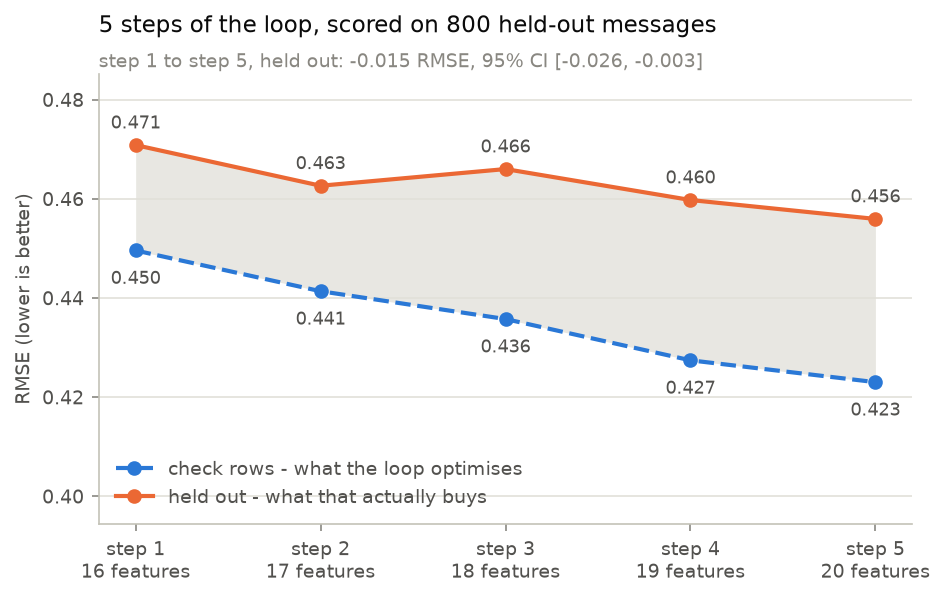

In [ ]:
curve, per_step = [], []
for features in snapshots:
    X_step, _ = design(features, answers_for, ENCODING)
    per_step.append(fit_predict(X_step, split))
    curve.append((len(features), rmse(SCORES[TEST], per_step[-1])))

# the same held-out rows resampled 2,000 times, both arms scored on each resample
gain = paired_gain(SCORES[TEST], per_step[0], per_step[-1])
print(
    f"step 1 -> step {len(snapshots)} on the held-out rows: {gain[0]:+.3f} RMSE, "
    f"95% CI [{gain[1]:+.3f}, {gain[2]:+.3f}]"
)

# The docs build sets COOKSAFE_RENDER and also draws a dark copy.
for theme in ("light", "dark") if os.environ.get("COOKSAFE_RENDER") else ("light",):
    fig = steps_chart(plt, curve, history, len(TEST), gain, CHART_PALETTES[theme])
    display(fig, metadata={"theme": theme})
    plt.close(fig)

Both lines stay inside a band 0.05 wide, and the three approaches from the table that use
no questions would sit above the top of this chart. Check-row error fell at every step,
from 0.450 to 0.423. Held-out error fell from 0.471 to 0.456, with one rise along the way,
at step 3. The interval under the title runs from -0.026 to -0.003, which leaves out zero,
so the four steps after the first lowered held-out error by more than the noise.

Each later step kept one new question, and the log above shows them: `offer_of_assistance`
in step 2, `informal_slang_register` in step 3, `explicit_politeness_marker` in step 4 and
`defensive_self_justification` in step 5. Steps 2 and 5 needed more than one try. In step
2, every change from the first try failed the check. The second try saw that list with
each change's error, proposed something else, and its offer-of-help question cut check-row
error by 0.009. Step 5 took all three tries.

Most of the turned-down questions go after narrower kinds of impoliteness than step 1
asked about: rhetorical challenges, backhanded courtesy, negative labels for the reader, a
lecturing tone. Each one raised check-row error or lowered it by less than `MIN_GAIN`. The
proposer also tried rewording six of its step-1 questions and dropping two. Every one of
those changes failed the check, so the step-1 wording stayed.

In [ ]:
kinds = {f["name"]: f["kind"] for f in accepted}
print("feature importance share: % of total CatBoost importance across all questions")
print(f"{'feature':<40}{'asked as':<10}{'importance share':>16}")
for name, importance_share in sorted(feature_importances.items(), key=lambda p: -p[1])[
    :12
]:
    kind = "score" if kinds[name] == "intensity" else "noul"
    print(
        f"{name[:38]:<40}{kind:<10}{importance_share:>8.1f}%  "
        f"{'#' * round(importance_share)}"
    )
counts = f"{sum(1 for k in kinds.values() if k == 'intensity')} score"
counts += f", {sum(1 for k in kinds.values() if k == 'presence')} noul"
print(f"\nthe {len(accepted)} questions the loop kept: {counts}")
top = max(feature_importances, key=feature_importances.get)
print(
    f'the question behind the top row:\n  {top}: "{owner_of(top, accepted)["question"]}"'
)

feature importance share: % of total CatBoost importance across all questions
feature                                 asked as  importance share
hostile_accusation                      score         11.8%  ############
explicit_politeness_marker              noul           9.4%  #########
curt_terseness                          score          9.1%  #########
positive_framing_of_reader              score          8.4%  ########
rudeness_insult                         score          7.9%  ########
doubt_questioning_competence            score          6.9%  #######
gratitude_or_praise                     score          6.3%  ######
sarcasm_or_mockery                      score          6.3%  ######
exclamatory_emotion                     score          5.6%  ######
personal_criticism_of_edit              score          5.4%  #####
blunt_command                           score          3.5%  ####
offer_of_assistance                     score          3.3%  ###

the 20 questions the loop k

The `importance share` column is CatBoost's feature importance, scaled so all the questions
in the final set add up to 100%. It is not a share of rows, of questions, or of prediction
accuracy. A `Score` question has two columns, its mean and its spread, so their two
importances are added together before the percentage is printed.

The top of the list is about hostility: `hostile_accusation` accounts for 11.8% on its own,
and `curt_terseness`, `rudeness_insult` and `doubt_questioning_competence` are close
behind. For the 2013 study this corpus comes from,
[Danescu-Niculescu-Mizil and colleagues](https://aclanthology.org/P13-1025/) built 20
politeness strategies by hand. Their impolite ones are surface forms: negative-sentiment
words, direct questions, "in fact", and a request that opens with "please" or "you". The
loop's top questions judge the tone instead: whether the writer accuses the reader, is
curt, insults them, or doubts their competence.

Several of the study's polite strategies made the set too. Three rank high:
`explicit_politeness_marker` ("please" and similar, second at 9.4%),
`positive_framing_of_reader` (the study's deference, such as praise for the reader's work)
and `gratitude_or_praise`. Greetings, hedging, asking with a "we" and asking indirectly
are in the set as well, each under 3%.

## Next steps

This run keeps the loop small. Ways to extend it:

- Screen a proposed question before paying to answer it for every row. Send the question
  itself to Jev as the state and ask `Noul` questions about it: can it be answered from the
  source text, does it mean one thing given its criteria, will its answer vary across rows.
  Answer only the questions that pass all three with a high enough probability.
- Remove near-duplicate questions. Measure how closely the columns track each other on the
  dev rows, group the near-duplicates, and keep the clearest or most important question
  from each group.
- Add simple baselines. Try TF-IDF (word counts weighted toward rarer words), character
  counts and other measures of the text's shape on their own. Then add them to the
  discovered columns and measure what each one adds.
- Use proposers from different model makers. Generate batches of questions with Anthropic,
  OpenAI, Google Gemini and open-source models, then merge them and remove duplicates
  before any reach Jev. Different model makers should produce a wider range of questions
  than repeated calls to one proposer.
- Try other models. Fit linear or elastic-net regression, a support vector regressor, or a
  random forest on the same columns, and check whether the discovered questions help
  outside CatBoost. If the value you predict is a probability, also try recalibrating it so
  predicted probabilities match observed rates.
- Add an embedding baseline. An embedding turns a message into a few hundred numbers with
  no question attached: `sentence-transformers/all-MiniLM-L6-v2` runs locally, OpenAI's
  `text-embedding-3-small` is a hosted call. Add one to the discovered columns and measure
  whether it carries anything they do not.
- Split the data the way the model will be used. If you predict the future, split by
  date. If related rows must stay together, split by group. Keep a final test set that
  neither the loop nor your choice of model ever touches.
- Change the stopping rule. Raise `TRIES` or `MAX_STEPS` for a longer search, or stop at a
  budget of Jev requests instead of a count of proposal calls.
- Run a longer search in an agent's Goal mode. Give it a metric, a budget and a rule for
  when to stop, then let it run more steps of proposing, scoring and revising.
- Check which questions hold up. Rerun the loop with different seeds or data samples, and
  keep the questions that stay useful across runs, not the ones that matter on only one
  split.

## Open it in the playground

The link below opens the TypeSafe playground with one request and every question the loop
kept.

In [ ]:
playground_link = make_playground_link(
    {"message": MESSAGES[0]}, feature_questions(accepted)
)
display(
    Markdown(
        f"🔗 [Open the message + questions in the TypeSafe playground]({playground_link})"
    )
)

🔗 [Open the message + questions in the TypeSafe playground](https://console.typesafe.ai/playground#share/N4IgJg9gxgrgtgUwHYBcAqCAeKQC4AEIwAOiIgM7kCGA5gqQaWgBZVIDW+AnhDPgGYQATvihUUUZgEskNfAGkkEAO5IBwhUuUA6fPgASK-GClhuvfKwAOV5PhQR8AGwgRO4+8wT4qQlFKgnBAB+UgBfEAAaQishCDgrFHIMbDxCEhAhGDBkBEoAfRlyGCcUBnwMlC5bctJyKGF6KPxSIpQsqH8IJHJakAARCDzPbwpqOlFulCoZfCKSpOikKkQAWjEnJxkaaI0G1AQElBhecnwhQ992M6oAI14UEfOEKhyhAHIzhoSEFGQoBDRGR-TZSOhIAG7ESSXxUToIIShZqkKBCKR-NFUcoAbVIADkII9YnlkI9ZihpGcxrRvB4qJtSNFSAAhXwIJxcfDE8ik-CrHz4cjbIKCuD0pz2IRwppMkAABQuPNQPkeVHwcAgb3E3iCADd2YyWvLFbzyO1ujQOXy5o8xUJrk9lMwICLqXRDaRBnAZGxHvyKaM8uNvFIzjl+DIEGZbpz0aQALphWXOs1SIL5OGwahdJDlSrVJqMED1RoekBtDo53ppT1DM4B-DKNEYnxQLPeBsXV4I-AQfiNuKySDbaK3V4CGYUqHGUNZRJSfX4W4IVi6qQaWZq-b8QfTHP0xtULhI2Wo9EIqRYtK4kAEokm5XkynqoM0lU+BnIkCsi5W7m8-k1SFWQRXIMVNklaUywVEllTpdVNQRbVnAQfUnGgh9HjNQdLU5fl0XVK56y8RtnVdV93S-L0fWVf0SLdEMwwQCMkCjJdYzKEBE1lGgpX8Y4cnyYR8liGYeTzUgqhqGtiwaC4ywrGBOnXHo+kGYYGwYzw2E4TsXjeXtoXiKwtkQZUAykERlGEdhomYwQ-GnO403RKQ8hPI0zwxS8cXxQkuUwuY1ApUMX0oN86U-WUf3ZTl-1ogVgMtbwwPFSCAQw2DVVVBCtT+FC0MypUsPNEC8JtQj7WI7wnRdQNwso2VqOWBLNIoxjjGYyNow4hMkyNcg+z+JBtnyLwwDoasCHzaSixLeSv0U5Tuimo11OqgdzxEGAeUFIbkG2Zw2BoGA32KSQfBuKwXQgGg3PIaJxsm6csG5IUVt7fsYAhBFpmBTllwc0YqHYQ6LJEC4AEcYDyFAPJRZsLyvAgbzvAKsqCzxQq0yL0K-GK-0CwDBWFFLwIldooK-GDivfNUNTynVUINanAuwi0rXw20iMdMj6uDMtmt9a02oajrw269ibT6niLl+UbhNeMBFVWmbCyNJQSgUnp2iUqs1LrJ4tIgWw1GUdFmAFXiEHl2RomoJwYD3FTpx3NykDAK0lZV+xHD07sRAACnOy2qBufBlkQR72RcachW9JxfC5IIw99IQuAASnhkAvKRiSQF19WmHo9rBWdZRiNCvYU6EK0pASLZhjjL9+HpcSZJYfm3zu-UziUIKTDEHNPqx6swn60hbkd1B8m+MUPfzqSi9k0tFp1ysVNW2sNJLsX8B22kl2nskfj4hdvA0HJ57MPivBECk2C5ZgpSSp4oZhs1LoFaHYZUwyuRdOeS67Bs650xL5W8-l4pkmCs+HGqoopGgJnFImiVSaijSpTDKrMMbwQZkhfKeoWayhpqaUquFrQETtA6BstVyJi0FvEGifojal1ChLViPVpZcQnsWXwYgwJCSEPkDUUB2AIi4IvAsfR5oyiNEtfWMl1qsL3vsfUnJqBCAEXAaIojxHpycpMD2eQAQezBt0DsKhfBmH9m8UBiNwHXj8veDGT5sal1xmWZB6NabEySqBcm6U5GkFIXBHK+C+JM0Kjg2m7MyqUO5lVXmdUwoCyokwlqLDRbBjmExFibEYzcO4kaV6idlg5nyD3ZAUjZoa14HjWUCjN4Gx3jVBx+BSkzFgQgSyvZVDPDDt0EcRi-jYGnAAKx2v4CMQ8-4OTfggH+n9AaNGAYddE9ito+TSJULIy9O6pLOuXSuZxq4vFrrGBu91uGylbk4duRYDlaSqX3RwMhB7iD-n2Ue4ReHXSFP4fU+QdwrAVvwfIXY3g1OXrI7W2E9bNKUYbbJb5Xo+yoDYC4UBLw5miK8b0Z9ujTn+a5RcFwaDWPUPfEikKESfFbFWf+MIpTwkRGWMB2yUbOJ8byNxVIPEIIaUgtkhMMZ+PQalCCWDgnGlweExCkSCrEKNKEkqOFOYVWoRtOhXdGprQycLOiurxZdU4VLZuxSUQwD8PkDESogzQpkXJGVTSVp9AAJIbS0lgdohxYpl2EKqD2PhbhzhQNEROYjDpsE5OyO4whPlEuTi8agqA0R5DjvtEashGzCDAOQTZ3lkb4FRlAwKfLDkTE8fjEVKCxVoJAmTTBLKZWqrprlAhUTlUhLZuQjVVCea0L5pWmVQtWq7xyew01BTeo8NlEsip1CRKAOGg6nZklpEyVhWveFy1VIyU9QshdT8X5sTDlbZAMBIy7FNvgBdf8ZBrn8Dm2xdKzgyCsE7c44g77aTUOeoCe4-XKivmwEwObvgmUvD9QtecnGQJcbTCt8CPxCpZLWnlCUgISsCdKoqvI8EKuQkQtDsrYl9vKgOpJQ6UkMUYd6TJIsJ1vinfkrhFreFYECCscQwguD5EOISFSjqt3OrhbrPdW8BjIuYxMA+HTMDcbFMPa6wIHqofWBi9TGhCS-uoQiU5-Y4lyEE-uCUwJkAAs5BoLAYdbCEqQLBxxXKEOYZgaPEddNEHod-HW3xDbkoYKlS2-DYSBQROI8zUjbbjP9sSTQkiOqR30eYUx41uTOpsfNZxS1IB7ODWWE4WezYAihjgEJcFUZm7TQ3bUuoYmd0ScUUWZRtD2leVKwALwviINFQYBBZGwom-99wv1AVsNimZDK-6vvvq4WycwG5cHWY8ZQ56mwWn-t9ZQ7JvghHZQ4zlJbuXQMxiFfle9q3RQw6d8VjagsUxCzEgj8rGZKui729VlH4vauHXR9JDHDUqMnXkyWhSOOnhdIne4Z8gUOFYiJuaDXGnrwRW6pFrTNothBYgI9H9VTh3IKwC4Zg9hQ-jbD7w9lA3RB2odMpJ03xbHEYKGANBJrPrkO8Hb7xc32l9nQAMEMf09gfmoUDZic2DUQCFHN3QrTfNm05o7pbEO8tge4y7gqvE3dQdh+7krHtUxIYFQjb2SOhbVRzb7lUEs1T++1FLjGjWedY2D2duXIAwFuCgfI96hmyFnsZX4-x1ZqydavFHu7mv6sx1peuJkNHiPnNisC-8vc+5DQ8BZAd6XfTeGaMDwznSsTNFwackGQ8wYO1s4tqu3NnbgQK1DOvfMN7u4Fw3QTLftoi4QqLPfYs261ck+haSmoGvHelt3Zrwc5d4e8yyCBOgQsWfjxHA1kfyNR5Jj1G136wxPWHNii+sUoA5PbJSocbjkFBjmp0vxf3S8f+ss4-yhRTx66RR-ouaX6R7NZCUNGDVGmFsHbN+kLn+jOGflaCCGAXIAGHAKRB4A4MYBAMrnXiduWhrhdjkldsKm3rdgFgEs2sbiqqbq9p2u9oPhRgkrbr9rRo7gDqli7vHqDrPh7rwn2PwAiBVhmJQKGNMD9BvvVpHtvtHoii1jJm0ltAFBAHCICv6twaLo4F4E4FYNELqC6N9H8L-j0iICoGoNTo5P-H1pQI2KAdsKXvWI4GHEKJ-LNtELfL-o-JMp-GHHfggX-gHL7GgXtDLtILIBgRAmjKdshs3uKK3v6kQfrp3rhk9ibnKuFkRv3tEokeRl9nQSPjRmPjSE7kDiihMDPjOkUgvkgA5OBPkOQAzqvndGaAiCISvAtFHk1pIbHl6qXPJgIqdBKNUcdNEA0JsBANDJeBKPsFglWNOBZkIKxCgKsGXiKDIBUQeFYM-GHIdIHMzt4O8FwC8MwO8NEO8DQN0MsAcfgO8F0u8CgGcZfHEDYGxLxCsHaBnNpNzOIhtPDt4DweyJ9PwKwMGhoN9NdFsETmxM4dSo-GIBcPwCUFaJBhADyGAMEfBqEdgR5ihpETWoQXriTAbvEWQT2kkfTCkV2h9hjEPlkYOolg7gwswc7sDixuwSURDiUpgFBtir7sCeeNYSIlcA0eugXJukWJrKRq6vulIXHmwhCI7DkD4EYWyVsByZMNan8OQJyNZEIKTiIKsaet-moGKJ4TaGcAfmaJfhdOeu8CZCmggGcdzvUmYDwHwAxmADcSIO8FIP2I6cqU4C6fbGCIVodDkFsMuIqlyaupQMiTVgXHsn0E8qXETioCckyjXHXFck3JxLcm3PsrJt4C8hHG8mYrMt0CPOdr8rKOGJZufFUeyOCm4dMgEMNo0dui0RvOjhKdqu0hWT0OfFaJ0rMBoHWR6ZyODH0moLEOuCIAoX-IHOeibP8mxKgYOfwMti+n-seuiDyE4PwBnGadfp1EgCuXIBtkOBAIdNXL4EOYdE6CgV4JyAoT0VaCYGAKOMxKsh4WDF4L0v7o5jXkWiEWWq4jgZ5vgT5tETif4k2sFgSWRi9skebgPs9sqBSVzPQaPsavkVPq7kyexvPhENECABilIAAGoGYqRpAgC6gACMIAYQQAA)